<a href="https://colab.research.google.com/github/pratapsingh23/uk-road-accident-severity-prediction/blob/main/eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px


from data_loading import data_loading, files
df = data_loading(files['final_df'])

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 513801 entries, 0 to 513800
Data columns (total 51 columns):
 #   Column                                             Non-Null Count   Dtype         
---  ------                                             --------------   -----         
 0   collision_index                                    513801 non-null  object        
 1   collision_severity                                 513801 non-null  int64         
 2   date                                               513801 non-null  datetime64[ns]
 3   day_of_week                                        513801 non-null  int64         
 4   time                                               513801 non-null  object        
 5   latitude                                           513748 non-null  float64       
 6   longitude                                          513748 non-null  float64       
 7   urban_or_rural_area                                513793 non-null  float64       
 8   spee

#**Exploratary Data Anyalysis**


##**Accident Severity Analysis**

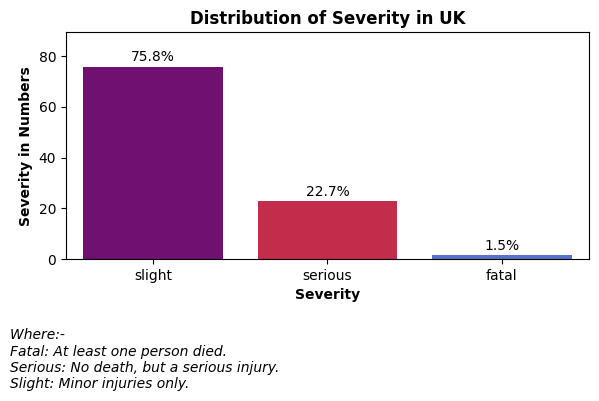

In [4]:
# Distribution of Fatal, Serious and Slight accidents:

order = ['fatal', 'slight', 'serious']

dist = (
    df['collision_severity_label']
    .value_counts()
    .reindex(order)
    .rename('count')
    .reset_index()
    .rename(columns={'index': 'severity', 'collision_severity_label': 'severity'})
)
dist['percent'] = ((dist['count'] / dist['count'].sum()) * 100).round(2)
dist = dist.sort_values('count', ascending=False)

# plot
fig, ax = plt.subplots(figsize=(6,4))
colors = {
    'fatal': 'royalblue',
    'slight': 'purple',
    'serious': 'crimson'
}
sns.barplot(
    data=dist,
    x='severity',
    y='percent',
    hue='severity',
    palette=colors,
    ax=ax
)

for c in ax.containers:
  ax.bar_label(c, fmt=f"%1.1f%%", padding=2)


ax.set_ylim(0, dist['percent'].max() * 1.18)
ax.set_title("Distribution of Severity in UK", fontweight='bold')
ax.set_xlabel("Severity", fontweight='semibold')
ax.set_ylabel("Severity in Numbers", fontweight='semibold')
fig.supxlabel("Where:- \nFatal: At least one person died. \nSerious: No death, but a serious injury. \nSlight: Minor injuries only.", x=0.01, ha='left', style='italic',  fontsize=10)
plt.tight_layout()
plt.savefig('distribution_severity.png', dpi=200)
plt.show()

### **Insights:**

- Only **1.5%** of accidents are fatal.
- Around **22.7%** of accidents are serious.
- About **75.8%** of accidents are slight.

This means that **75 out of every 100 accidents** are neither serious nor fatal — they involve only minor injuries.

##**Rural vs Urban severity comparison.**

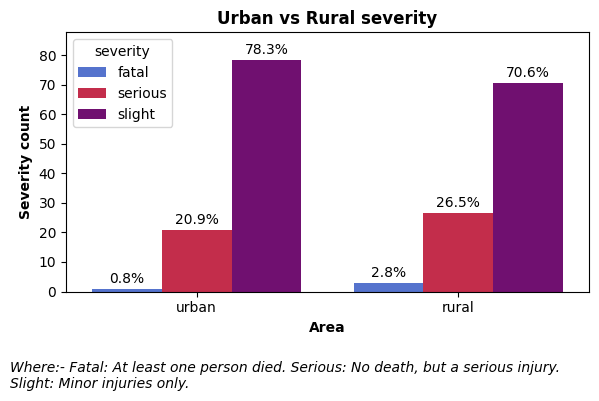

In [5]:
# Rural vs Urban severity comparison.

severity = ['fatal', 'serious', 'slight']
area = ['urban', 'rural']

severity_area = df[
    df['collision_severity_label'].isin(severity) &
    df['urban_or_rural_area_label'].isin(area)
].copy()

# cross table
sev_result = pd.crosstab(
    severity_area['urban_or_rural_area_label'].rename('area'),
    severity_area['collision_severity_label'].rename('severity')
)[['fatal', 'serious', 'slight']].reindex(['urban', 'rural'])



plot_df = sev_result.reset_index().melt(id_vars='area',
                                        var_name='severity',
                                        value_name='count')

plot_df['pct'] = (plot_df['count'] / plot_df.groupby('area')['count'].transform('sum') * 100).round(2)

# barplot
fig, ax = plt.subplots(figsize=(6,4))
sns.barplot(
    data=plot_df,
    x='area',
    y='pct',
    hue='severity',
    palette=colors,
    ax=ax
)

# pct label
for c in ax.containers:
  ax.bar_label(c, fmt=f"%1.1f%%", padding=2)


ax.set_ylim(0, plot_df['pct'].max() * 1.12)
ax.set_title("Urban vs Rural severity", fontweight='bold')
ax.set_xlabel("Area", fontweight='semibold')
ax.set_ylabel("Severity count", fontweight='semibold')
fig.supxlabel("Where:- Fatal: At least one person died. Serious: No death, but a serious injury. \nSlight: Minor injuries only.", x=0.01, ha='left', style='italic',  fontsize=10)
plt.tight_layout()
plt.savefig('urban_vs_rural.png', dpi=200)
plt.show()


### **Insights:**

**In Urban:**
- **78.3%** of accidents are slight.
- **20.9%** are serious.
- Only **0.8%** are fatal.

**In Rural:**
- **70.6%** of accidents are slight.
- **26.5%** are serious.
- Only **2.8%** are fatal.

So, it can be said that **fatal accidents are higher in rural areas compared to urban areas**.

##**Severity pattern by Season**

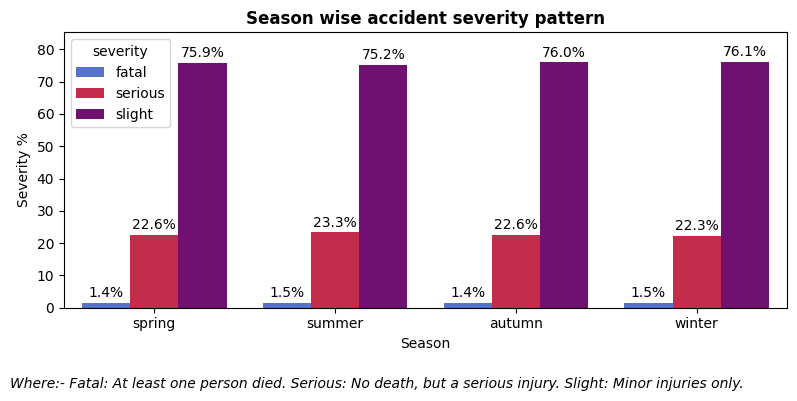

In [6]:

# Season Accident pattern
df['month'] = df['date'].dt.month

# season mapping
season_map = {
    3: "spring", 4: "spring", 5: "spring",
    6: "summer", 7: "summer", 8: "summer",
    9: "autumn", 10: "autumn", 11: "autumn",
    12: "winter", 1: "winter", 2: "winter"

}
df['season'] = df['month'].map(season_map)

# severity-season

severity = ['fatal', 'serious', 'slight']
season_severity = df[
    df['collision_severity_label'].isin(severity) &
    df['season']
]
season_result = pd.crosstab(
    season_severity['season'],
    season_severity['collision_severity_label'].rename('severity')
    )[['fatal', 'serious', 'slight']].reindex(['spring', 'summer', 'autumn', 'winter'])

season_plot = season_result.reset_index().melt(id_vars='season',
                                               var_name='severity',
                                               value_name='count')

season_plot['percent'] = (season_plot['count'] / season_plot.groupby('season')['count'].transform('sum') * 100).round(2)

# ploting
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(
    data=season_plot,
    x='season',
    y='percent',
    hue='severity',
    palette=colors,
    ax=ax
)

for c in ax.containers:
  ax.bar_label(c, fmt=f"%1.1f%%", padding=2)

ax.set_title("Season wise accident severity pattern", fontweight='bold')
ax.set_xlabel("Season")
ax.set_ylabel("Severity %")
ax.set_ylim(0, season_plot['percent'].max() * 1.12)
fig.supxlabel("Where:- Fatal: At least one person died. Serious: No death, but a serious injury. Slight: Minor injuries only.", x=0.01, ha='left', style='italic',  fontsize=10)
plt.savefig('season_wise_acc.png', dpi=200)
plt.tight_layout()
plt.show()

### **Insights:**

- After looking at the bar chart, it is observed that **all seasons have a similar accident severity distribution**.
- It **cannot be said** that any particular season — such as winter — shows different results.

##**Morning vs Evening accidents**

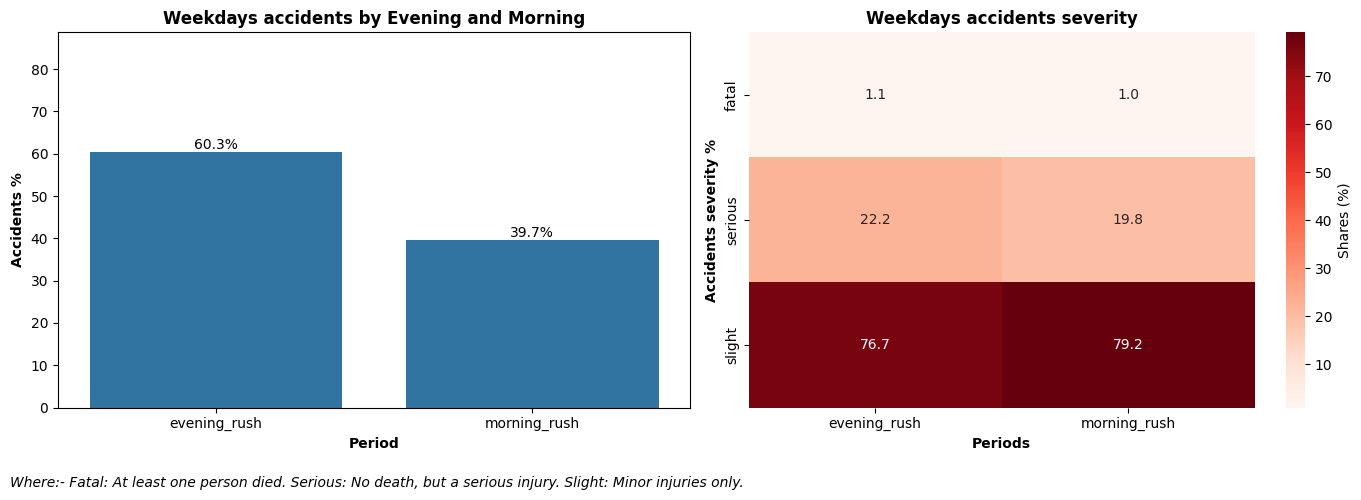

In [7]:
# Morning rush hour vs evening rush hour?
df['hours'] = pd.to_datetime(df['time'], format="%H:%M", errors='coerce').dt.hour


weekdays = df[df['day_of_week'].isin([1, 2, 3, 4, 5])]

conditions = [
    weekdays['hours'].between(7, 9),
    weekdays['hours'].between(16, 18)
]
choices = ['morning_rush', 'evening_rush']

weekdays = weekdays.assign(period=np.select(conditions, choices, default='others'))
rush = weekdays[weekdays['period'] != 'others']

counts = rush.groupby(['period', 'collision_severity_label']).size().reset_index(name='count')

counts['percent'] = (counts['count'] / counts.groupby('period')['count'].transform('sum') * 100).round(2)
pivot = counts.pivot(index='collision_severity_label', columns='period', values='percent')

# Overall Accidents:
acc_rush = rush.groupby('period')['collision_index'].size().reset_index(name='count')
acc_rush['percent'] = (acc_rush['count'] / acc_rush['count'].sum() * 100).round(2)



# Plot-

fig, axes = plt.subplots(1, 2, figsize=(14,5))
# Accidentd overall
sns.barplot(
    data=acc_rush,
    x='period',
    y='percent',
    ax=axes[0]
)
# accidents overall
sns.heatmap(
    pivot,
    annot=True,
    fmt='.1f',
    cbar_kws={'label': 'Shares (%)'},
    cmap='Reds',
    ax=axes[1]
)
# Adding more details-

for c in axes[0].containers:
  axes[0].bar_label(c, fmt='%1.1f%%')
axes[0].set_ylim(0, counts['percent'].max() * 1.12)
axes[0].set_title("Weekdays accidents by Evening and Morning", fontweight='bold')
axes[0].set_xlabel("Period", fontweight='semibold')
axes[0].set_ylabel("Accidents %", fontweight='semibold')

axes[1].set_title("Weekdays accidents severity", fontweight='bold')
axes[1].set_xlabel("Periods", fontweight='semibold')
axes[1].set_ylabel("Accidents severity %", fontweight='semibold')

fig.supxlabel("Where:- Fatal: At least one person died. Serious: No death, but a serious injury. Slight: Minor injuries only.", x=0.01, ha='left', style='italic',  fontsize=10)
plt.tight_layout()
plt.savefig('weekdays_acc.png', dpi=200)
plt.show()


### **Insights:**

**Weekday Accidents (Evening vs Morning):**
- **60.3%** of weekday accidents occur during the **evening rush**, while **39.7%** occur in the **morning**.
- So, it can be observed that in the UK, most accidents happen in the **evening** compared to the morning.

**Severity in Weekdays:**
- **Evening:** Slight — **76.7%**, Serious — **22.2%**, Fatal — **1.1%**
- **Morning:** Slight — **79.2%**, Serious — **19.8%**, Fatal — **1.0%**
- So, in the **evening**, accidents tend to be **more serious/injury-related** compared to the morning.

**Final Verdict:** Generally, travelling in the **morning is safer than in the evening**. However, this does **not** mean the morning is completely safe.

##**Severity pattern of pedestrian involved accidents**

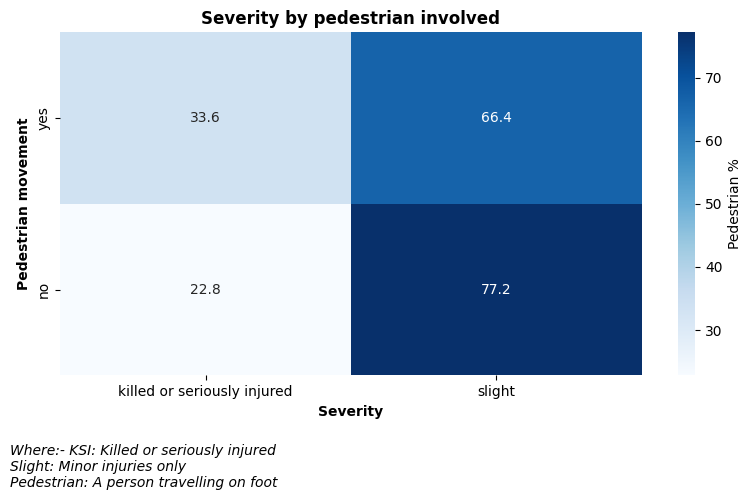

In [8]:
# Severtiy of pedestrian involved accidents
df['has_pedestrian_movement'].value_counts()
df['ksi'] = df['collision_severity'].isin([1, 2])
ksi = {
    'fatal': "killed or seriously injured",
    'serious': "killed or seriously injured",
    'slight': 'slight'
}
df['collision_severity_label_new'] = df['collision_severity_label'].map(ksi)
pedestrain = df.groupby('has_pedestrian_movement')['collision_severity_label'].size()

change_name = {1: 'yes', 0: 'no'}

pedestrian_df = (pd.crosstab(
    df['has_pedestrian_movement'].map(change_name),
    df['collision_severity_label_new'],
    normalize='index'
) * 100).round(2)[['killed or seriously injured', 'slight']].reindex(['yes', 'no'])


# plotting
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(
    pedestrian_df,
    annot=True,
    fmt=".1f",
    cmap='Blues',
    cbar_kws={'label': 'Pedestrian %'},
    ax=ax
)
ax.set_title("Severity by pedestrian involved", fontweight='bold')
ax.set_xlabel("Severity", fontweight='semibold')
ax.set_ylabel("Pedestrian movement", fontweight="semibold")
fig.supxlabel("Where:- KSI: Killed or seriously injured \nSlight: Minor injuries only \nPedestrian: A person travelling on foot", x=0.01, ha='left', style='italic',  fontsize=10)
plt.tight_layout()
plt.savefig('severity_pedestrian.png', dpi=200)
plt.show()

### **Insights**

> **Note:** Percentages below are **row-wise** — each group (pedestrian: yes / no) totals 100%.

**When Pedestrian Movement is NOT Involved:**
- **77.2%** of accidents are slight (minor injuries only).
- **22.8%** of accidents are KSI (Killed or Seriously Injured).

**When Pedestrian Movement IS Involved:**
- **66.4%** of accidents are slight.
- **33.6%** of accidents are KSI (Killed or Seriously Injured).

**Key Takeaway:**
- Accidents **without pedestrian involvement** are mostly **slight (77.2%)**, with only **22.8%** resulting in KSI.
- Accidents **with pedestrian involvement** show a **noticeably higher KSI share (33.6%)**, even though slight injuries still dominate (66.4%).
- This means **pedestrian-involved accidents are more likely to result in death or serious injury** compared to accidents where no pedestrian is involved — the KSI share nearly **1.5× higher** (33.6% vs. 22.8%).

##**Severity by Deprived band**

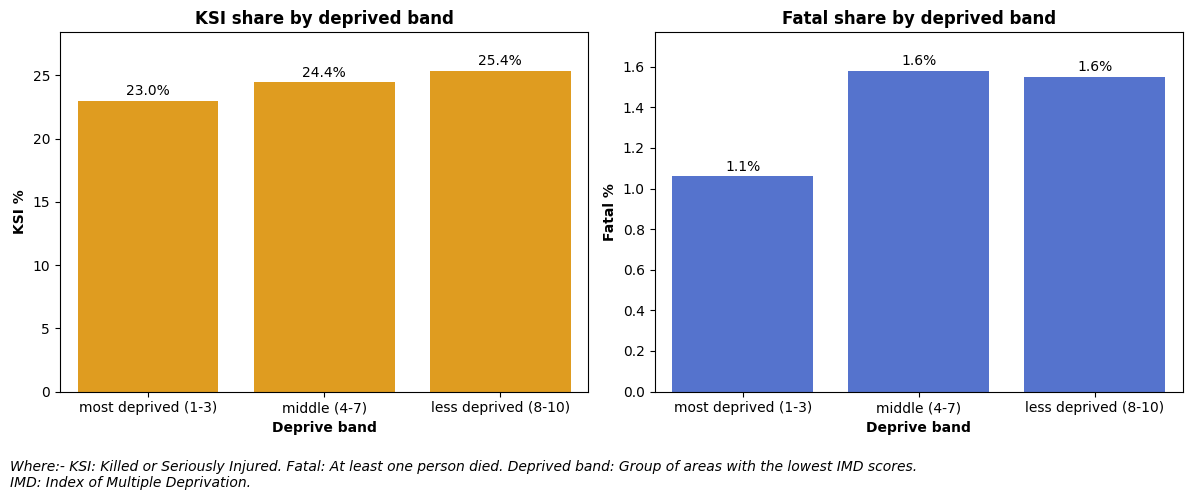

In [9]:
# severity of deprived band

d = df.dropna(subset=['avg_casualty_imd']).copy()
d['ksi'] = df['collision_severity'].isin([1, 2])
d['fatal'] = df['collision_severity'].eq(1)
d['imd_band'] = pd.cut(d['avg_casualty_imd'],
                       bins=[0, 3, 7, 10],
                       labels=['most deprived (1-3)', 'middle (4-7)', 'less deprived (8-10)'])
res = (d.groupby('imd_band', observed=True)
          .agg(
              total=('ksi', 'size'),
              ksi_pct=('ksi', 'mean'),
              fatal_pct=('fatal', 'mean')
          ))
res[['ksi_pct', 'fatal_pct']] = (res[['ksi_pct', 'fatal_pct']] * 100).round(2)

# plot
r = res.reset_index()
fig, axes = plt.subplots(1,2, figsize=(12, 5))

sns.barplot(
    data=r,
    x='imd_band',
    y='ksi_pct',
    color='orange',
    ax=axes[0]
)

sns.barplot(
    data=r,
    x='imd_band',
    y='fatal_pct',
    color='royalblue',
    ax=axes[1]
)

axes[0].set_title("KSI share by deprived band", fontweight='bold')
axes[0].set_xlabel("Deprive band", fontweight='semibold')
axes[0].set_ylabel("KSI %", fontweight='semibold')
axes[0].set_ylim(0, r['ksi_pct'].max() * 1.12)
for c in axes[0].containers:
  axes[0].bar_label(c, fmt='%1.1f%%', padding=2)

axes[1].set_title("Fatal share by deprived band", fontweight='bold')
axes[1].set_xlabel("Deprive band", fontweight='semibold')
axes[1].set_ylabel("Fatal %", fontweight='semibold')
axes[1].set_ylim(0, r['fatal_pct'].max() * 1.12)
for c in axes[1].containers:
  axes[1].bar_label(c, fmt='%1.1f%%', padding=2)

fig.supxlabel("Where:- KSI: Killed or Seriously Injured. Fatal: At least one person died. Deprived band: Group of areas with the lowest IMD scores. \nIMD: Index of Multiple Deprivation.",x=0.01, ha='left', fontsize=10, style='italic')
plt.tight_layout()
plt.savefig('saverity_deprived.png', dpi=200)
plt.show()


### **Insights — Severity by Deprivation Band:**

**KSI (Killed or Seriously Injured) by Deprivation Band:**
- **Most deprived (1–3):** 23.0%
- **Middle (4–7):** 24.4%
- **Less deprived (8–10):** 25.4%

**Fatal Accidents by Deprivation Band:**
- **Most deprived (1–3):** 1.1%
- **Middle (4–7):** 1.6%
- **Less deprived (8–10):** 1.6%

**Key Takeaway:**
- The **KSI share increases** as deprivation decreases — from **23.0%** in the most deprived band to **25.4%** in the less deprived band.
- **Fatal accidents** are **lowest in the most deprived band (1.1%)** and slightly higher in the middle and less deprived bands (1.6% each).
- Overall, deprivation band shows only a **mild variation** in severity — the differences are small, so deprivation alone does not strongly explain accident severity.

In [10]:
geo = (df[[
    'latitude', 'longitude', 'urban_or_rural_area_label', 'speed_limit', 'collision_severity_label'
]].dropna(subset=('latitude', 'longitude'))).copy()

geo['ksi'] = geo['collision_severity_label'].isin(['fatal', 'serious'])
geo['is_urban'] = geo['urban_or_rural_area_label'].eq('urban')

geo['lat_g'] = geo['latitude'].round(2)
geo['long_g'] = geo['longitude'].round(2)

grid = (geo.groupby(['lat_g', 'long_g'])
              .agg(
                  total=('ksi', 'size'),
                  ksi_rate=('ksi', 'mean'),
                  urban_share=('is_urban', 'mean'),
                  avg_speed_limit=('speed_limit', 'mean')
              )).reset_index()

grid['ksi_rate'] = (grid['ksi_rate'] * 100).round(2)
grid['urban_share'] = (grid['urban_share'] * 100).round(0)

hot = grid[grid['total'] >= 50].copy()
hot['ksi_rate_capped'] = hot['ksi_rate'].clip(upper=50)
# print(len(grid), '->', len(hot) )

# plot:
fig = px.scatter_map(
    hot, lat='lat_g', lon='long_g',
    color='ksi_rate_capped', size='total', size_max=18,
    color_continuous_scale='YlOrRd',
    hover_data={
        'lat_g': False, 'long_g': False, 'total': True,
        'ksi_rate_capped': ':.1f', 'urban_share': ':.0f',
        'avg_speed_limit': ':.0f'
    },
    zoom=5, center={'lat': 55.3781, 'lon': -3.4360},  map_style='carto-positron',
    title="KSI rate by 1 km grid"
)
fig.write_html('ksi_rate_map.html', include_plotlyjs='cdn')
fig.show()

The Graph can view by below link: